In [1]:
import sys
sys.path.append('../')

import numpy as np
from joblib import Parallel, delayed

from weighted_conformal_clustering.utils import label_alignment, soft_predict, conformal_narc, scale_weights

import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

from sklearn.neighbors import KNeighborsClassifier
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score, accuracy_score

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import ListedColormap
from matplotlib import colors as mcolors
from matplotlib.patches import FancyArrowPatch

In [2]:
# ==========================================
# Exact Network Architecture
# ==========================================
# We must define the exact same class so PyTorch knows how to load the weights.

class ConvAutoencoder(nn.Module):
    def __init__(self, latent_dim=10):
        super(ConvAutoencoder, self).__init__()
        
        self.encoder_conv = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=0), nn.ReLU()
        )
        self.encoder_fc = nn.Linear(1152, latent_dim)
        
        self.decoder_fc = nn.Linear(latent_dim, 1152)
        self.decoder_conv = nn.Sequential(
            nn.ConvTranspose2d(128, 64, kernel_size=3, stride=2, padding=0), nn.ReLU(),
            nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, output_padding=1), nn.ReLU(),
            nn.ConvTranspose2d(32, 1, kernel_size=3, stride=2, padding=1, output_padding=1), nn.Sigmoid() 
        )

    def forward(self, x):
        encoded = self.encoder_conv(x)
        encoded = encoded.view(encoded.size(0), -1) 
        z = self.encoder_fc(encoded)
        return z  # We only need the latent representation 'z' for clustering


# Settings
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
LATENT_DIM = 10
MODEL_PATH = f"Results/MNIST_AE_{LATENT_DIM}d.pth"
DATA_ROOT = "./Data"
K = 10

print(f"Loading model onto {DEVICE}...")

# 1. Initialize and load the Autoencoder
autoencoder = ConvAutoencoder(latent_dim=LATENT_DIM).to(DEVICE)

# Load the weights (since we saved the unwrapped model, it loads cleanly)
try:
    autoencoder.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
except FileNotFoundError:
    print(f"Error: Could not find '{MODEL_PATH}'. Please ensure the path is correct.")
    exit()
    
autoencoder.eval() # Set to evaluation mode

# 2. Load the MNIST Test Set
transform = transforms.Compose([transforms.ToTensor()])
test_dataset = datasets.MNIST(root=DATA_ROOT, train=False, download=True, transform=transform)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

# 3. Extract Features
print("Extracting 10D features from the 10,000 test images...")
features = []
true_labels = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(DEVICE)
        z = autoencoder(x)
        features.append(z.cpu().numpy())
        true_labels.append(y.numpy())
        
# Convert lists to single numpy arrays
X_10d = np.concatenate(features, axis=0)
y_true = np.concatenate(true_labels, axis=0)

print(f"Extraction complete. Feature array shape: {X_10d.shape}\n")

# Full GMM on the 10D features (just to see how it does)
gmm = GaussianMixture(n_components=10, random_state=42, n_init=5)
gmm_labels = gmm.fit_predict(X_10d)

print("ARI for GMM Clustering:", adjusted_rand_score(y_true, gmm_labels))
gmm_alignment = label_alignment(y_true, gmm_labels, K=10)
gmm_labels_aligned = gmm_alignment[gmm_labels]
print("Accuracy for GMM Clustering:", accuracy_score(y_true, gmm_labels_aligned))

Loading model onto cpu...
Extracting 10D features from the 10,000 test images...
Extraction complete. Feature array shape: (10000, 10)

ARI for GMM Clustering: 0.7182285848948873
Accuracy for GMM Clustering: 0.7982


In [3]:
# # first obtain 10 folds for stratified cross-validation, then run the experiment on each fold
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
folds = list(skf.split(X_10d, y_true))

results = []
for fold_idx, (tr_cal_idx, val_idx) in enumerate(folds):
    print(f"Running fold {fold_idx+1}/10...")
    X_fold, y_fold = X_10d[tr_cal_idx], y_true[tr_cal_idx]
    X_tr, X_cal, y_tr, y_cal = train_test_split(X_fold, y_fold, test_size=0.5, random_state=fold_idx, stratify=y_fold)
    X_val, y_val = X_10d[val_idx], y_true[val_idx]

    n_tr = X_tr.shape[0]
    n_cal = X_cal.shape[0]
    n_val = X_val.shape[0]

    clf = KNeighborsClassifier(n_neighbors=int(np.sqrt(n_tr)))
    gmm_tr = GaussianMixture(n_components=K, max_iter=200, n_init=5, random_state=0)
    gmm_tr.fit(X_tr)
    gmm_tr_prob = gmm_tr.predict_proba(X_tr)
    y_tr_gmm = soft_predict(gmm_tr_prob, seed=0)
    clf.fit(X_tr, y_tr_gmm)

    cal_prob = clf.predict_proba(X_cal)
    y_cal_hat = clf.predict(X_cal)
    
    # Pre-fit a GMM on X_cal to use for warm-starting the augmented GMMs.
    # This saves an enormous amount of computation time since we avoid fitting from scratch per validation point.
    gmm_cal = GaussianMixture(n_components=K, max_iter=200, n_init=5, random_state=0)
    gmm_cal.fit(X_cal)

    def conformal_set(x, alpha=0.1, clip_min=1e-6):
        X_aug = np.vstack([X_cal, x]) # x has to be (1, n_features) for vstack to work
        
        # Warm start using the calibration GMM parameters, reducing n_init to 1
        gmm_aug = GaussianMixture(
            n_components=K, 
            max_iter=200, 
            n_init=1, 
            random_state=0,
            weights_init=gmm_cal.weights_,
            means_init=gmm_cal.means_,
            precisions_init=gmm_cal.precisions_
        )
        gmm_aug.fit(X_aug)
        gmm_aug_prob = gmm_aug.predict_proba(X_aug)
        gmm_cal_prob = gmm_aug_prob[:n_cal, :]
        y_cal_gmm = soft_predict(gmm_cal_prob, seed=0)
        gmm_cal_weight = gmm_cal_prob[np.arange(n_cal), y_cal_gmm]
        gmm_test_weight = gmm_aug_prob[-1, :]

        test_prob = clf.predict_proba(x)

        
        # align using the augmented data (most probable clusters)
        y_aug_hat = np.append(y_cal_hat, clf.predict(x))
        y_aug_gmm = np.argmax(gmm_aug_prob, axis=1)
        align_to_tr = label_alignment(y_aug_hat, y_aug_gmm, K=K)
        y_cal_al = align_to_tr[y_cal_gmm]

        # weights with clipped denominators (test weights in classifier-label order)
        weight_cal_numerator = cal_prob[np.arange(n_cal), y_cal_al]
        weight_cal_raw = weight_cal_numerator / np.maximum(gmm_cal_weight, clip_min)

        weight_test_numerator = test_prob
        gmm_test_weight_al = gmm_test_weight[np.argsort(align_to_tr)]
        weight_test_raw = weight_test_numerator / np.maximum(gmm_test_weight_al, clip_min)

        # set weights to 1 when both the numerator and the denominator are very small
        weight_cal_raw[(weight_cal_numerator < clip_min) & (gmm_cal_weight < clip_min)] = 1.0
        weight_test_raw[(weight_test_numerator < clip_min) & (gmm_test_weight_al < clip_min)] = 1.0

        weight = scale_weights(weight_cal_raw, weight_test_raw)

        conformal_set_bool = conformal_narc(cal_prob, y_cal_al, test_prob, weight=weight, alpha=alpha)
        return np.where(conformal_set_bool[0])[0]


    conformal_sets = Parallel(n_jobs=-1, verbose=1)(delayed(conformal_set)(X_val[i].reshape(1, -1)) for i in range(n_val))

    # align 
    oracle_alignment = label_alignment(y_tr, y_tr_gmm, K=K)
    conformal_sets_aligned = [oracle_alignment[cs] for cs in conformal_sets]

    coverage = np.mean([y_val[i] in conformal_sets_aligned[i] for i in range(len(X_val))])

    size = np.mean([len(cs) for cs in conformal_sets_aligned])

    results.append((coverage, size))

Running fold 1/10...


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 10 concurrent workers.
[Parallel(n_jobs=-1)]: Done  30 tasks      | elapsed:    1.8s
[Parallel(n_jobs=-1)]: Done 820 tasks      | elapsed:    3.4s
[Parallel(n_jobs=-1)]: Done 1000 out of 1000 | elapsed:    3.8s finished


Running fold 2/10...


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 10 concurrent workers.
[Parallel(n_jobs=-1)]: Done  40 tasks      | elapsed:    0.1s
[Parallel(n_jobs=-1)]: Done 960 tasks      | elapsed:    2.0s
[Parallel(n_jobs=-1)]: Done 1000 out of 1000 | elapsed:    2.1s finished


Running fold 3/10...


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 10 concurrent workers.
[Parallel(n_jobs=-1)]: Done  40 tasks      | elapsed:    0.1s
[Parallel(n_jobs=-1)]: Done 960 tasks      | elapsed:    2.0s
[Parallel(n_jobs=-1)]: Done 1000 out of 1000 | elapsed:    2.1s finished


... (10 outputs left out)

Running fold 9/10...


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 10 concurrent workers.
[Parallel(n_jobs=-1)]: Done  40 tasks      | elapsed:    0.1s
[Parallel(n_jobs=-1)]: Done 960 tasks      | elapsed:    2.1s
[Parallel(n_jobs=-1)]: Done 1000 out of 1000 | elapsed:    2.3s finished


Running fold 10/10...


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 10 concurrent workers.
[Parallel(n_jobs=-1)]: Done  40 tasks      | elapsed:    0.1s
[Parallel(n_jobs=-1)]: Done 953 tasks      | elapsed:    2.2s
[Parallel(n_jobs=-1)]: Done 1000 out of 1000 | elapsed:    2.3s finished


In [14]:
# average results across folds
avg_coverage = np.mean([r[0] for r in results])
std_coverage = np.std([r[0] for r in results])
avg_size = np.mean([r[1] for r in results])
std_size = np.std([r[1] for r in results])

print(f"Average Coverage across folds: {avg_coverage:.3f} (SD: {std_coverage:.3f})")
print(f"Average Size across folds: {avg_size:.3f} (SD: {std_size:.3f})")

Average Coverage across folds: 0.872 (SD: 0.050)
Average Size across folds: 1.868 (SD: 0.064)


In [5]:
# split into 45/45/10 train/cal/val sets
id = np.arange(X_10d.shape[0])
X_tr, X_temp, y_tr, y_temp, id_tr, id_temp = train_test_split(X_10d, y_true, id, test_size=0.55, random_state=42, stratify=y_true)
X_cal, X_val, y_cal, y_val, id_cal, id_val = train_test_split(X_temp, y_temp, id_temp, test_size=2/11, random_state=42, stratify=y_temp)

n_tr = X_tr.shape[0]
n_cal = X_cal.shape[0]
n_val = X_val.shape[0]

clf = KNeighborsClassifier(n_neighbors=int(np.sqrt(n_tr)))
gmm_tr = GaussianMixture(n_components=K, max_iter=200, n_init=5, random_state=0)
gmm_tr.fit(X_tr)
gmm_tr_prob = gmm_tr.predict_proba(X_tr)
y_tr_gmm = soft_predict(gmm_tr_prob, seed=0)
clf.fit(X_tr, y_tr_gmm)

cal_prob = clf.predict_proba(X_cal)
y_cal_hat = clf.predict(X_cal)

# Pre-fit a GMM on X_cal to use for warm-starting the augmented GMMs.
# This saves an enormous amount of computation time since we avoid fitting from scratch per validation point.
gmm_cal = GaussianMixture(n_components=K, max_iter=200, n_init=5, random_state=0)
gmm_cal.fit(X_cal)

def conformal_set(x, alpha=0.1, clip_min=1e-6):
    X_aug = np.vstack([X_cal, x]) # x has to be (1, n_features) for vstack to work
    # gmm_aug = GaussianMixture(n_components=K, max_iter=200, n_init=5, random_state=0)
    # Warm start using the calibration GMM parameters, reducing n_init to 1
    gmm_aug = GaussianMixture(
        n_components=K, 
        max_iter=200, 
        n_init=1, 
        random_state=0,
        weights_init=gmm_cal.weights_,
        means_init=gmm_cal.means_,
        precisions_init=gmm_cal.precisions_
    )
    gmm_aug.fit(X_aug)
    gmm_aug_prob = gmm_aug.predict_proba(X_aug)
    gmm_cal_prob = gmm_aug_prob[:n_cal, :]
    y_cal_gmm = soft_predict(gmm_cal_prob, seed=0)
    gmm_cal_weight = gmm_cal_prob[np.arange(n_cal), y_cal_gmm]
    gmm_test_weight = gmm_aug_prob[-1, :]

    test_prob = clf.predict_proba(x)

    
    # align using the augmented data (most probable clusters)
    y_aug_hat = np.append(y_cal_hat, clf.predict(x))
    y_aug_gmm = np.argmax(gmm_aug_prob, axis=1)
    align_to_tr = label_alignment(y_aug_hat, y_aug_gmm, K=K)
    y_cal_al = align_to_tr[y_cal_gmm]

    # weights with clipped denominators (test weights in classifier-label order)
    weight_cal_numerator = cal_prob[np.arange(n_cal), y_cal_al]
    weight_cal_raw = weight_cal_numerator / np.maximum(gmm_cal_weight, clip_min)

    weight_test_numerator = test_prob
    gmm_test_weight_al = gmm_test_weight[np.argsort(align_to_tr)]
    weight_test_raw = weight_test_numerator / np.maximum(gmm_test_weight_al, clip_min)

    # set weights to 1 when both the numerator and the denominator are very small
    weight_cal_raw[(weight_cal_numerator < clip_min) & (gmm_cal_weight < clip_min)] = 1.0
    weight_test_raw[(weight_test_numerator < clip_min) & (gmm_test_weight_al < clip_min)] = 1.0

    weight = scale_weights(weight_cal_raw, weight_test_raw)

    conformal_set_bool = conformal_narc(cal_prob, y_cal_al, test_prob, weight=weight, alpha=alpha)
    return np.where(conformal_set_bool[0])[0]


conformal_sets = Parallel(n_jobs=-1, verbose=1)(delayed(conformal_set)(X_val[i].reshape(1, -1)) for i in range(n_val))

# align 
oracle_alignment = label_alignment(y_tr, y_tr_gmm, K=K)
conformal_sets_aligned = [oracle_alignment[cs] for cs in conformal_sets]

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 10 concurrent workers.
[Parallel(n_jobs=-1)]: Done  40 tasks      | elapsed:    0.1s
[Parallel(n_jobs=-1)]: Done 960 tasks      | elapsed:    2.2s
[Parallel(n_jobs=-1)]: Done 1000 out of 1000 | elapsed:    2.3s finished


In [6]:
coverage = np.mean([y_val[i] in conformal_sets_aligned[i] for i in range(len(X_val))])
print(f"Coverage on the validation set: {coverage:.3f}")

size = np.mean([len(cs) for cs in conformal_sets_aligned])
print(f"Average size of the conformal sets: {size:.3f}")

size_dist, size_counts = np.unique([len(cs) for cs in conformal_sets_aligned], return_counts=True)
for s, c in zip(size_dist, size_counts):
    print(f"Size {s}: {c} sets ({c/n_val:.2%})")

val_covered = np.array([y_val[i] in conformal_sets_aligned[i] for i in range(len(X_val))])
id_val_covered = id_val[val_covered]
id_val_missed = id_val[~val_covered]

# identify points with set size >= 3
id_val_uncertain = id_val[[len(cs) >= 3 for cs in conformal_sets_aligned]]

Coverage on the validation set: 0.918
Average size of the conformal sets: 1.897
Size 1: 430 sets (43.00%)
Size 2: 362 sets (36.20%)
Size 3: 129 sets (12.90%)
Size 4: 50 sets (5.00%)
Size 5: 22 sets (2.20%)
Size 6: 4 sets (0.40%)
Size 7: 2 sets (0.20%)
Size 8: 1 sets (0.10%)


In [7]:
tsne = TSNE(n_components=2, random_state=42)
# original test data
#X_test = test_dataset.data.numpy().reshape(-1, 28*28) / 255.0
#X_2d = pca.fit_transform(X_test)
#X_2d = tsne.fit_transform(X_test)
X_2d = tsne.fit_transform(X_10d)


In [8]:
id_trcal = np.concatenate([id_tr, id_cal])
X_2d_trcal = X_2d[id_trcal]
y_trcal = y_true[id_trcal]
X_2d_val = X_2d[id_val]
X_2d_val_covered = X_2d[id_val_covered]
X_2d_val_missed = X_2d[id_val_missed]
y_val_covered = y_true[id_val_covered]
y_val_missed = y_true[id_val_missed]
n_val_covered = len(id_val_covered)
n_val_missed = len(id_val_missed)

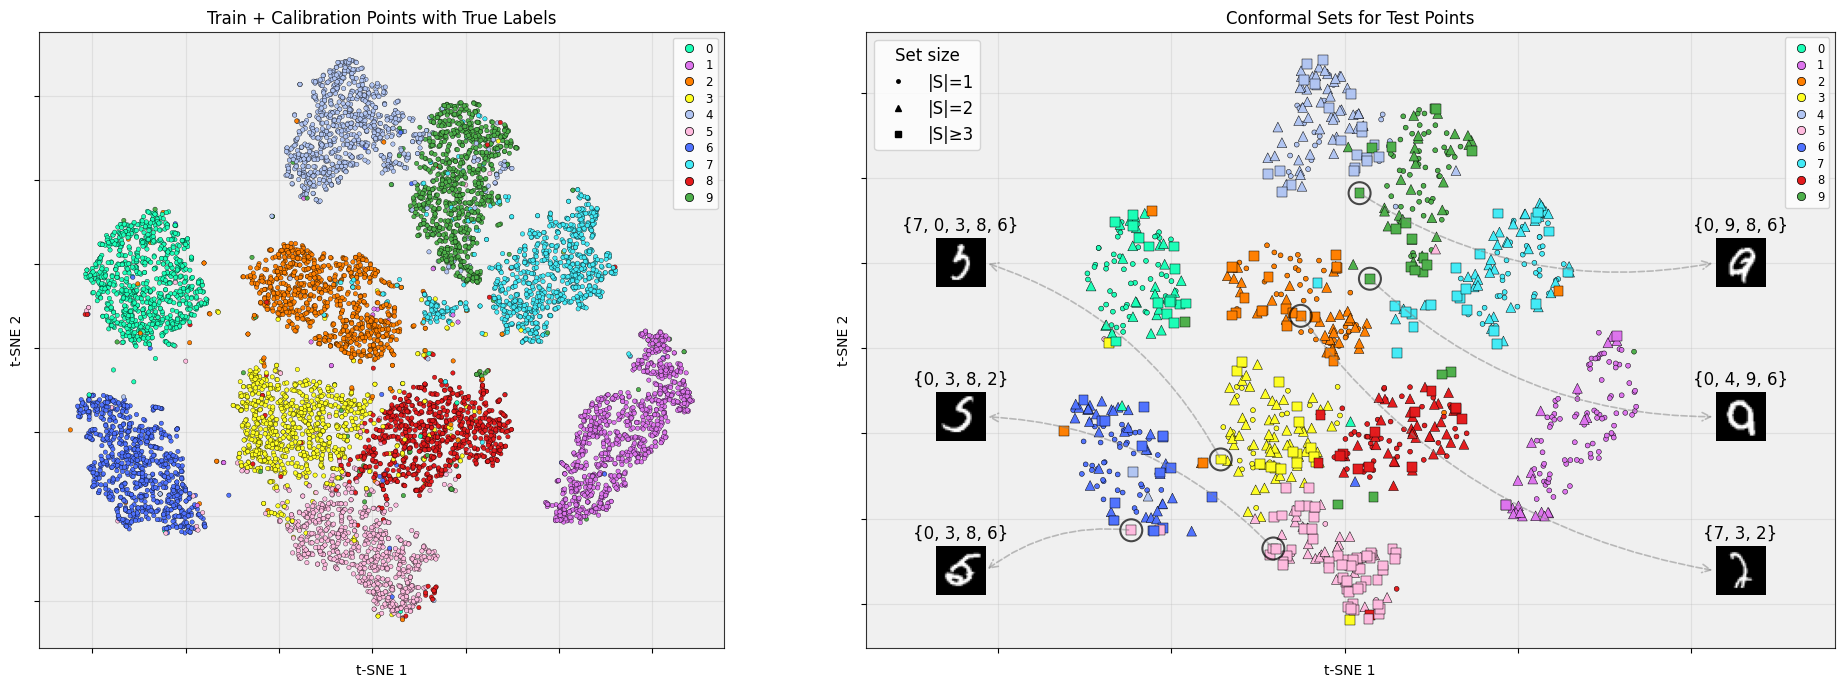

In [13]:
def style_ax(ax):
    ax.set_facecolor("#f0f0f0")
    ax.grid(True, alpha=0.25)
    ax.set_axisbelow(True)
    for sp in ax.spines.values():
        sp.set_alpha(0.8)
    ax.set_xlabel("t-SNE 1")
    ax.set_ylabel("t-SNE 2")

def make_category_palette(categories):
    pool = [
        "#1affb7","#dd74ed","#ff7f00","#ffff21","#b1c5f3","#ffbbdf","#4F72FF",
        "#42ebf7","#e41a1c","#4daf4a","#88CCEE","#e78ac3","#ffd92f","#e5c494","#b3b3b3",
        "#1f77b4","#ff7f0e","#2ca02c","#d62728","#9467bd","#8c564b","#e377c2","#7f7f7f",
        "#bcbd22","#17becf","#377eb8",
        "#332288","#117733","#44AA99","#a65628","#DDCC77","#CC6677","#AA4499","#882255","#999933"
    ]
    if len(categories) > len(pool):
        raise ValueError(f"Need {len(categories)} colors, but pool has only {len(pool)}.")
    palette = {cat: pool[i] for i, cat in enumerate(categories)}
    cmap = ListedColormap([palette[cat] for cat in categories])
    return palette, cmap

palette, hydra_cmap = make_category_palette(np.arange(20))
core_rgb = {k: np.array(mcolors.to_rgb(v), float) for k, v in palette.items()}

true_handles = [
    Line2D([0], [0], marker='o', linestyle='none',
           markersize=6,
           markerfacecolor=core_rgb[int(lab)],
           markeredgecolor='k', markeredgewidth=0.5,
           label=str(lab))
    for lab in np.unique(y_true).astype(int)
]


def lighten_toward_white(rgb, alpha):
    """alpha in [0,1]: 0 = no change, 1 = white."""
    return (1 - alpha) * rgb + alpha * 1.0

def labels_to_color(labels_like, n_classes=5, base_alpha=0.05):
    """
    - If labels_like is an int -> use that core color.
    - If it's an iterable -> take the mean of the cores in it,
      then 'intensify by number of labels' by moving toward white
      with alpha = base_alpha * (k-1), where k = set size.
      (More labels -> lighter background.) 
    """
    # normalize to a Python set of ints
    if isinstance(labels_like, (int, np.integer)):
        S = {int(labels_like)}
    else:
        S = {int(x) for x in labels_like}
        

    # empty set -> white
    if len(S) == 0:
        return np.array([1.0, 1.0, 1.0], float)

    # mean of the present cores
    mean_rgb = np.mean([core_rgb[i] for i in S], axis=0)

    # intensity control by subset size k
    k = len(S)
    alpha = min(1.0, base_alpha * (k - 1))  # more labels -> lighter
    return lighten_toward_white(mean_rgb, alpha)

def darken(rgb, factor=0.15):  # 0.15 = 15% darker
    return np.clip(rgb * (1 - factor), 0, 1)

dark_colors = {k: darken(core_rgb[k], 0.15) for k in core_rgb}


# Marker grouping helper
def marker_group(pred_sets):
    set_sizes = np.array([len(p) for p in pred_sets])
    return np.where(set_sizes == 1, 1, np.where(set_sizes == 2, 2, 3))

# Set-size legend handles (all black)
setsize_handles = [
    Line2D([0],[0], marker='.', linestyle='none',
           markerfacecolor='k', markeredgecolor='k', markersize=5, label='|S|=1'),
    Line2D([0],[0], marker='^', linestyle='none',
           markerfacecolor='k', markeredgecolor='k', markersize=5, label='|S|=2'),
    Line2D([0],[0], marker='s', linestyle='none',
           markerfacecolor='k', markeredgecolor='k', markersize=5, label='|S|≥3'),
]

# . for size 1, ^ for size 2, s for size 3 or more
marker_map = {1: ".", 2: "^", 3: "s"}

marker_group_test = marker_group(conformal_sets_aligned)

# confidence set colored based on the true label
test_colors = np.array([core_rgb[y_val[i]] for i in range(n_val)])

fig, axes = plt.subplots(1, 2, figsize=(25,8))
fig.patch.set_facecolor("white")

# make the second plot wider to accommodate thumbnails, while keeping the first plot compact
axes[0].set_box_aspect(0.9)

# remove the horizontal space between the two subplots
plt.subplots_adjust(wspace=0)

ax = axes[0]
style_ax(ax)
ax.set_title("Train + Calibration Points with True Labels")
ax.scatter(
    X_2d_trcal[:, 0], X_2d_trcal[:, 1],
    c=[core_rgb[label] for label in y_trcal],
    s=40, marker=".",
    edgecolors="black", linewidths=0.25, rasterized=True, alpha=0.99
)
ax.legend(handles=true_handles, loc="upper right",
          frameon=True, fontsize=8.5, title_fontsize=9,
          borderpad=0.4, labelspacing=0.3, handletextpad=0.4)

# hide the tick labels
ax.set_xticklabels([])
ax.set_yticklabels([])

ax = axes[1]
style_ax(ax)
ax.set_title("Conformal Sets for Test Points")
for g in [1, 2, 3]:
    idx = (marker_group_test == g)
    ax.scatter(
        X_2d_val[idx, 0], X_2d_val[idx, 1], 
        c=test_colors[idx],
        s=50, marker=marker_map[g], 
        edgecolors='black', linewidths=0.35, rasterized=True, alpha=0.99 
        )
leg_set = ax.legend(handles=setsize_handles, title="Set size", loc="upper left", frameon=True, fontsize=12, title_fontsize=12)
ax.add_artist(leg_set) 
ax.legend(handles=true_handles, loc="upper right",
          frameon=True, fontsize=8.3, title_fontsize=9,
          borderpad=0.4, labelspacing=0.3, handletextpad=0.4)

# choose uncertain points to display (size >= 3)
id_uncertain_display = [3723, 2380, 3599, 4740, 7498, 9749]
n_uncertain_display = len(id_uncertain_display)

# Get plot bounds for positioning thumbnails
xlim = ax.get_xlim()
ylim = ax.get_ylim()
x_range = xlim[1] - xlim[0]
y_range = ylim[1] - ylim[0]

# Position thumbnails 
thumb_spacing = y_range / (n_uncertain_display / 2 + 1)
thumb_size = 0.08 * y_range

# Place thumbnails vertically spaced
thumb_y_start = (ylim[0] + ylim[1]) / 2 + thumb_spacing / 2

for i, idx in enumerate(id_uncertain_display):
    
    # Highlight uncertain point with larger red circle
    ax.scatter(X_2d[idx, 0], X_2d[idx, 1], s=250, facecolors='none', 
               edgecolors='black', linewidths=1.5, marker='o', zorder=5, alpha=0.7)
    
    # Position thumbnail on the right side for the first half and left side for the second half
    if i < n_uncertain_display // 2:
        thumb_x_pos = xlim[1] + 0.08 * x_range  # right side
        thumb_y_pos = thumb_y_start - i * thumb_spacing
        inset_ax = ax.inset_axes(
            [thumb_x_pos, thumb_y_pos - thumb_size/2, thumb_size, thumb_size],
            transform=ax.transData)
    else:
        thumb_x_pos = xlim[0] - 0.08 * x_range  # left side
        thumb_y_pos = thumb_y_start - (i - n_uncertain_display // 2) * thumb_spacing
        inset_ax = ax.inset_axes(
            [thumb_x_pos - thumb_size, thumb_y_pos - thumb_size/2, thumb_size, thumb_size],
            transform=ax.transData)
   
    thumbnail = test_dataset.data[idx].numpy() / 255.0
    inset_ax.imshow(thumbnail, cmap='gray')
    inset_ax.axis('off')
    inset_ax.set_facecolor('white')
    # annotate with the predicted set
    pred_set = conformal_sets_aligned[np.where(id_val == idx)[0][0]]
    pred_set_str = ", ".join(str(s) for s in pred_set)
    inset_ax.set_title(f"{{{pred_set_str}}}", fontsize=12)
    
    # Draw arrow from uncertain point to thumbnail with curved path
    arrow = FancyArrowPatch(
        (X_2d[idx, 0], X_2d[idx, 1]),
        (thumb_x_pos, thumb_y_pos),
        arrowstyle='->', mutation_scale=15, linewidth=1.2,
        color='gray', alpha=0.5, zorder=4, linestyle='--',
        connectionstyle="arc3,rad=0.2"
    )
    ax.add_patch(arrow)

# enlarge the plot limits to accommodate thumbnails
ax.set_xlim(xlim[0] - 0.27 * x_range, xlim[1] + 0.27 * x_range)

# hide the tick labels
ax.set_xticklabels([])
ax.set_yticklabels([])

#fig.tight_layout()
plt.savefig("Figures/MNIST.pdf", bbox_inches='tight')
plt.show()